# 02 — Préparation des données pour le UNet


## 0. Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rioxarray
from scipy import ndimage

## 1. Paramètres

In [2]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

ANNEES = ["2021", "2022"]   # images utilisées pour l'entraînement

TAILLE_PATCH = 256        # pixels (= 2,56 km de côté)
MAX_SANS_DONNEE = 0.05    # on jette un patch s'il a plus de 5 % de pixels sans donnée satellite...
MAX_IGNORE = 0.30         # ... ou plus de 30 % de pixels ignorés au total (contours des feux, cultures brûlées)
BLOC = 4                  # un bloc géographique = 4 x 4 patchs (~10 x 10 km)
N_PLIS = 5                # validation croisée spatiale : 5 plis de blocs
PLI_TEST, PLI_VAL = 0, 1  # découpage principal : 1 pli test, 1 pli validation, 3 plis entraînement (60/20/20)
JEUX = ["train", "val", "test"]
GRAINE = 42               # pour que la répartition soit reproductible

MARGE_PERIMETRE = 3       # pixels (30 m) ignorés de part et d'autre du contour des périmètres EFFIS
SEUIL_BLOC_BRULE = 0.01   # un bloc est « touché par les feux » si >= 1 % de ses pixels 2022 sont brûlés

# Années de perte Hansen (21 = 2021...) dont les pixels sont ignorés, hors périmètres des feux
PERTES_HANSEN_IGNOREES = {"2021": [21], "2022": [21, 22]}

BANDES = ["B02", "B03", "B04", "B08", "B11", "B12"]
IGNORE = 255              # valeur des pixels à ignorer pendant l'entraînement

## 2. Regroupement des classes


In [3]:
CLASSES = {
    0: ("Forêt",               [10],     "#1a6b2a"),
    1: ("Végétation basse",    [20, 30], "#c8d96f"),
    2: ("Cultures",            [40],     "#f0b4e6"),
    3: ("Bâti",                [50],     "#d62728"),
    4: ("Sol nu / brûlé",      [60],     "#5c4033"),
    5: ("Eau / zones humides", [80, 90], "#2b6cb0"),
}
NOMS = [CLASSES[k][0] for k in sorted(CLASSES)]
CMAP = ListedColormap([CLASSES[k][2] for k in sorted(CLASSES)])
N_CLASSES = len(CLASSES)
BRULE = 4

# Dans un périmètre de feu 2022 : classes WorldCover qui deviennent « brûlé », et classes ignorées
WC_BRULABLES = [10, 20, 30, 60]
WC_INCERTAINES = [40]

## 3. Chargement

In [4]:
wc = rioxarray.open_rasterio(DATA_DIR / "worldcover_2021.tif").squeeze("band", drop=True)
lab_wc = wc.values
feux = rioxarray.open_rasterio(DATA_DIR / "feux_effis_2022.tif").squeeze("band", drop=True).values == 1
perte_hansen = rioxarray.open_rasterio(DATA_DIR / "hansen_perte_annee.tif").squeeze("band", drop=True).values

# Bande autour des contours EFFIS (30 m de chaque côté)
contour_feux = (ndimage.binary_dilation(feux, iterations=MARGE_PERIMETRE)
                & ~ndimage.binary_erosion(feux, iterations=MARGE_PERIMETRE))


def etiquettes(annee, image):
    """Étiquettes d'une année : WorldCover 2021, plus les périmètres des feux pour 2022."""
    y = np.full(lab_wc.shape, IGNORE, dtype=np.uint8)
    for k, (_, valeurs, _) in CLASSES.items():
        y[np.isin(lab_wc, valeurs)] = k
    y[np.isin(perte_hansen, PERTES_HANSEN_IGNOREES.get(annee, [])) & ~feux] = IGNORE   # coupes hors feux
    if annee == "2022":
        y[feux & np.isin(lab_wc, WC_BRULABLES)] = BRULE
        y[feux & np.isin(lab_wc, WC_INCERTAINES)] = IGNORE
        y[contour_feux] = IGNORE
    y[(image == 0).all(axis=0)] = IGNORE   # pas de donnée satellite -> ignoré
    return y


images, cibles = {}, {}
for annee in ANNEES:
    s2 = rioxarray.open_rasterio(DATA_DIR / f"s2_{annee}.tif")                # (bande, y, x)
    assert s2.shape[1:] == lab_wc.shape, f"Image {annee} et étiquettes n'ont pas la même grille"
    images[annee] = s2.values                      # uint16, réflectance x 10000
    cibles[annee] = etiquettes(annee, images[annee])
    print(f"{annee} : image {images[annee].shape}, pixels ignorés {(cibles[annee] == IGNORE).mean() * 100:.2f} %, "
          f"pixels « Sol nu / brûlé » {(cibles[annee] == BRULE).sum() * 100 / 10_000:,.0f} ha, "
          f"coupes Hansen ignorées {(np.isin(perte_hansen, PERTES_HANSEN_IGNOREES.get(annee, [])) & ~feux).sum() / 100:,.0f} ha")

2021 : image (6, 4650, 7674), pixels ignorés 1.04 %, pixels « Sol nu / brûlé » 1,225 ha, coupes Hansen ignorées 3,191 ha


2022 : image (6, 4650, 7674), pixels ignorés 2.05 %, pixels « Sol nu / brûlé » 27,174 ha, coupes Hansen ignorées 6,000 ha


## 4. Découpage en patchs
Un même emplacement donne un patch 2021 et un patch 2022. Chacun est gardé ou rejeté selon ses propres pixels (nuages, pixels ignorés).

In [5]:
H, W = lab_wc.shape
P = TAILLE_PATCH
n_lignes, n_cols = H // P, W // P


def patch_valide(annee, i, j):
    sans_donnee = (images[annee][:, i*P:(i+1)*P, j*P:(j+1)*P] == 0).all(axis=0).mean()
    ignores = (cibles[annee][i*P:(i+1)*P, j*P:(j+1)*P] == IGNORE).mean()
    return sans_donnee <= MAX_SANS_DONNEE and ignores <= MAX_IGNORE


positions = {annee: [(i, j) for i in range(n_lignes) for j in range(n_cols) if patch_valide(annee, i, j)]
             for annee in ANNEES}
lieux = sorted(set().union(*positions.values()))

print(f"Grille : {n_lignes} x {n_cols} = {n_lignes * n_cols} emplacements possibles")
for annee in ANNEES:
    print(f"  {annee} : {len(positions[annee])} patchs gardés")

Grille : 18 x 29 = 522 emplacements possibles
  2021 : 518 patchs gardés
  2022 : 522 patchs gardés


## 5. Répartition en plis géographiques


In [6]:
def part_brulee_bloc(b, bloc):
    if "2022" not in cibles:
        return 0.0
    bi, bj = b
    t = cibles["2022"][bi*bloc*P:(bi+1)*bloc*P, bj*bloc*P:(bj+1)*bloc*P]
    return float((t == BRULE).mean())


def attribuer_plis(lieux, bloc, graine):
    """Attribue un pli à chaque bloc, séparément pour les blocs touchés par les feux et les autres."""
    blocs = sorted({(i // bloc, j // bloc) for i, j in lieux})
    strates = {
        "touchés par les feux": [b for b in blocs if part_brulee_bloc(b, bloc) >= SEUIL_BLOC_BRULE],
        "autres": [b for b in blocs if part_brulee_bloc(b, bloc) < SEUIL_BLOC_BRULE],
    }
    rng = np.random.default_rng(graine)
    pli = {}
    for nom, liste in strates.items():
        rng.shuffle(liste)
        for k, b in enumerate(liste):
            pli[b] = k % N_PLIS        # distribution à tour de rôle
        print(f"  blocs {nom:22s}: {len(liste)} -> par pli {np.bincount([pli[b] for b in liste], minlength=N_PLIS).tolist()}")
    return pli


def jeu(pli):
    return "test" if pli == PLI_TEST else ("val" if pli == PLI_VAL else "train")


def decouper(bloc):
    pli_bloc = attribuer_plis(lieux, bloc, GRAINE)
    pli_de = lambda i, j: pli_bloc[(i // bloc, j // bloc)]
    split = {s: [(a, i, j) for a in ANNEES for i, j in positions[a] if jeu(pli_de(i, j)) == s] for s in JEUX}
    plis = {s: [pli_de(i, j) for _, i, j in split[s]] for s in JEUX}
    return pli_bloc, split, plis


pli_bloc, split, plis = decouper(BLOC)
if min(len(v) for v in split.values()) == 0:
    # Petite zone (mode test du notebook 01) : pas assez de blocs -> blocs de 1 patch
    print("Zone trop petite pour des blocs de", BLOC, "-> blocs de 1 patch")
    BLOC = 1
    pli_bloc, split, plis = decouper(BLOC)

for s, pos in split.items():
    detail = ", ".join(f"{a} : {sum(p[0] == a for p in pos)}" for a in ANNEES)
    print(f"{s:5s} : {len(pos)} patchs ({detail})")

  blocs touchés par les feux  : 10 -> par pli [2, 2, 2, 2, 2]
  blocs autres                : 30 -> par pli [6, 6, 6, 6, 6]
train : 627 patchs (2021 : 313, 2022 : 314)
val   : 200 patchs (2021 : 100, 2022 : 100)
test  : 213 patchs (2021 : 105, 2022 : 108)


## 6. Extraction des patchs et normalisation

In [7]:
def extraire(pos):
    X = np.stack([images[a][:, i*P:(i+1)*P, j*P:(j+1)*P] for a, i, j in pos]).astype(np.float32) / 10000
    Y = np.stack([cibles[a][i*P:(i+1)*P, j*P:(j+1)*P] for a, i, j in pos])
    return X, Y


donnees = {s: extraire(pos) for s, pos in split.items()}

# Moyenne et écart-type par bande, calculés UNIQUEMENT sur l'entraînement (2021 et 2022 ensemble)
X_train = donnees["train"][0]
MOYENNE = X_train.mean(axis=(0, 2, 3))
ECART = X_train.std(axis=(0, 2, 3)) + 1e-6
print(pd.DataFrame({"bande": BANDES, "moyenne": MOYENNE.round(4), "écart-type": ECART.round(4)}))

  bande  moyenne  écart-type
0   B02   0.0273      0.0255
1   B03   0.0466      0.0312
2   B04   0.0444      0.0413
3   B08   0.2254      0.0868
4   B11   0.1615      0.0819
5   B12   0.0968      0.0711


## 7. Répartition des classes et poids


In [8]:
lignes = []
for s, (_, Y) in donnees.items():
    annees_s = np.array([p[0] for p in split[s]])
    for a in ANNEES:
        Ya = Y[annees_s == a]
        valides = Ya[Ya != IGNORE]
        comptes = np.bincount(valides, minlength=N_CLASSES)
        for k in range(N_CLASSES):
            lignes.append({"jeu": f"{s} {a}", "classe": NOMS[k], "part_%": comptes[k] / max(comptes.sum(), 1) * 100})
repartition = pd.DataFrame(lignes).pivot(index="classe", columns="jeu", values="part_%").round(2)
repartition = repartition.loc[NOMS, [f"{s} {a}" for s in JEUX for a in ANNEES]]
display(repartition)

Y_train = donnees["train"][1]
freq = np.bincount(Y_train[Y_train != IGNORE], minlength=N_CLASSES).astype(float)
freq /= freq.sum()
POIDS = np.where(freq > 0, 1 / np.sqrt(np.maximum(freq, 1e-12)), 0.0)
POIDS = POIDS / POIDS[freq > 0].mean()
for k in range(N_CLASSES):
    alerte = "  <- absente de l'entraînement !" if freq[k] == 0 else ""
    print(f"{NOMS[k]:22s} fréquence {freq[k]*100:6.2f} %   poids {POIDS[k]:.2f}{alerte}")

jeu,train 2021,train 2022,val 2021,val 2022,test 2021,test 2022
classe,,,,,,
Forêt,61.03,55.72,52.75,43.67,56.87,48.41
Végétation basse,21.71,20.47,24.16,21.51,21.50,19.15
Cultures,7.90,7.87,12.30,12.31,10.83,10.58
Bâti,2.97,3.01,2.29,2.34,2.72,2.87
Sol nu / brûlé,0.40,6.55,0.51,12.05,0.10,9.01
Eau / zones humides,5.99,6.38,7.99,8.12,7.97,9.99


Forêt                  fréquence  58.39 %   poids 0.35
Végétation basse       fréquence  21.09 %   poids 0.59
Cultures               fréquence   7.89 %   poids 0.96
Bâti                   fréquence   2.99 %   poids 1.56
Sol nu / brûlé         fréquence   3.46 %   poids 1.45
Eau / zones humides    fréquence   6.18 %   poids 1.09


## 8. Sauvegarde

In [9]:
for s, (X, Y) in donnees.items():
    Xn = ((X - MOYENNE[None, :, None, None]) / ECART[None, :, None, None]).astype(np.float16)
    np.savez(DATA_DIR / f"patchs_{s}.npz", X=Xn, y=Y,
             positions=np.array([(i, j) for _, i, j in split[s]]),
             annee=np.array([int(a) for a, _, _ in split[s]]),
             pli=np.array(plis[s]))
    print(f"-> data/patchs_{s}.npz  X{Xn.shape}  y{Y.shape}")

config = {
    "bandes": BANDES,
    "annees": ANNEES,
    "classes": {int(k): {"nom": v[0], "worldcover": v[1], "couleur": v[2]} for k, v in CLASSES.items()},
    "classe_brulee": BRULE,
    "etiquettes_2022": {"source_feux": "EFFIS (data/feux_effis_2022.geojson)",
                        "worldcover_brulables": WC_BRULABLES, "worldcover_ignorees": WC_INCERTAINES,
                        "marge_contour_pixels": MARGE_PERIMETRE},
    "ignore": IGNORE,
    "taille_patch": TAILLE_PATCH,
    "bloc": BLOC,
    "graine": GRAINE,
    "n_plis": N_PLIS, "pli_test": PLI_TEST, "pli_val": PLI_VAL,
    "pertes_hansen_ignorees": PERTES_HANSEN_IGNOREES,
    "moyenne": MOYENNE.tolist(),
    "ecart_type": ECART.tolist(),
    "poids_classes": POIDS.tolist(),
    "n_patchs": {s: {a: sum(p[0] == a for p in pos) for a in ANNEES} for s, pos in split.items()},
}
with open(DATA_DIR / "config_patchs.json", "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print("-> data/config_patchs.json")

-> data/patchs_train.npz  X(627, 6, 256, 256)  y(627, 256, 256)
-> data/patchs_val.npz  X(200, 6, 256, 256)  y(200, 256, 256)


-> data/patchs_test.npz  X(213, 6, 256, 256)  y(213, 256, 256)
-> data/config_patchs.json


## 9. Vérifications visuelles


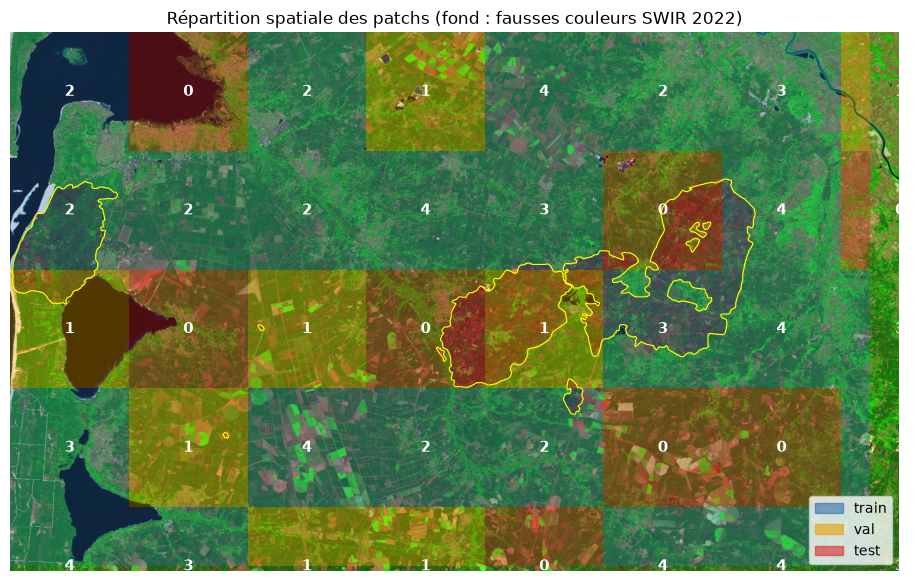

In [10]:
def fausses_couleurs(img, pas=4):
    arr = np.stack([img[5], img[3], img[2]], axis=-1)[::pas, ::pas].astype(np.float32)   # B12, B08, B04
    return np.clip(arr / 4500, 0, 1)


couleurs_split = {"train": "#2b6cb0", "val": "#e69f00", "test": "#d62728"}
pas = 4
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(fausses_couleurs(images[ANNEES[-1]], pas))
for s, pos in split.items():
    for i, j in sorted({(i, j) for _, i, j in pos}):
        ax.add_patch(plt.Rectangle((j*P/pas, i*P/pas), P/pas, P/pas,
                                   fill=True, alpha=0.35, color=couleurs_split[s], lw=0))
for (bi, bj), k in pli_bloc.items():
    ax.text((bj + 0.5) * BLOC * P / pas, (bi + 0.5) * BLOC * P / pas, str(k),
            ha="center", va="center", fontsize=11, color="white", weight="bold")
ax.contour(feux[::pas, ::pas], levels=[0.5], colors="yellow", linewidths=0.8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in couleurs_split.values()]
ax.legend(handles, list(couleurs_split), loc="lower right")
ax.set_title(f"Répartition spatiale des patchs (fond : fausses couleurs SWIR {ANNEES[-1]})")
ax.axis("off")
plt.savefig(FIG_DIR / "repartition_patchs.png", dpi=200, bbox_inches="tight")
plt.show()

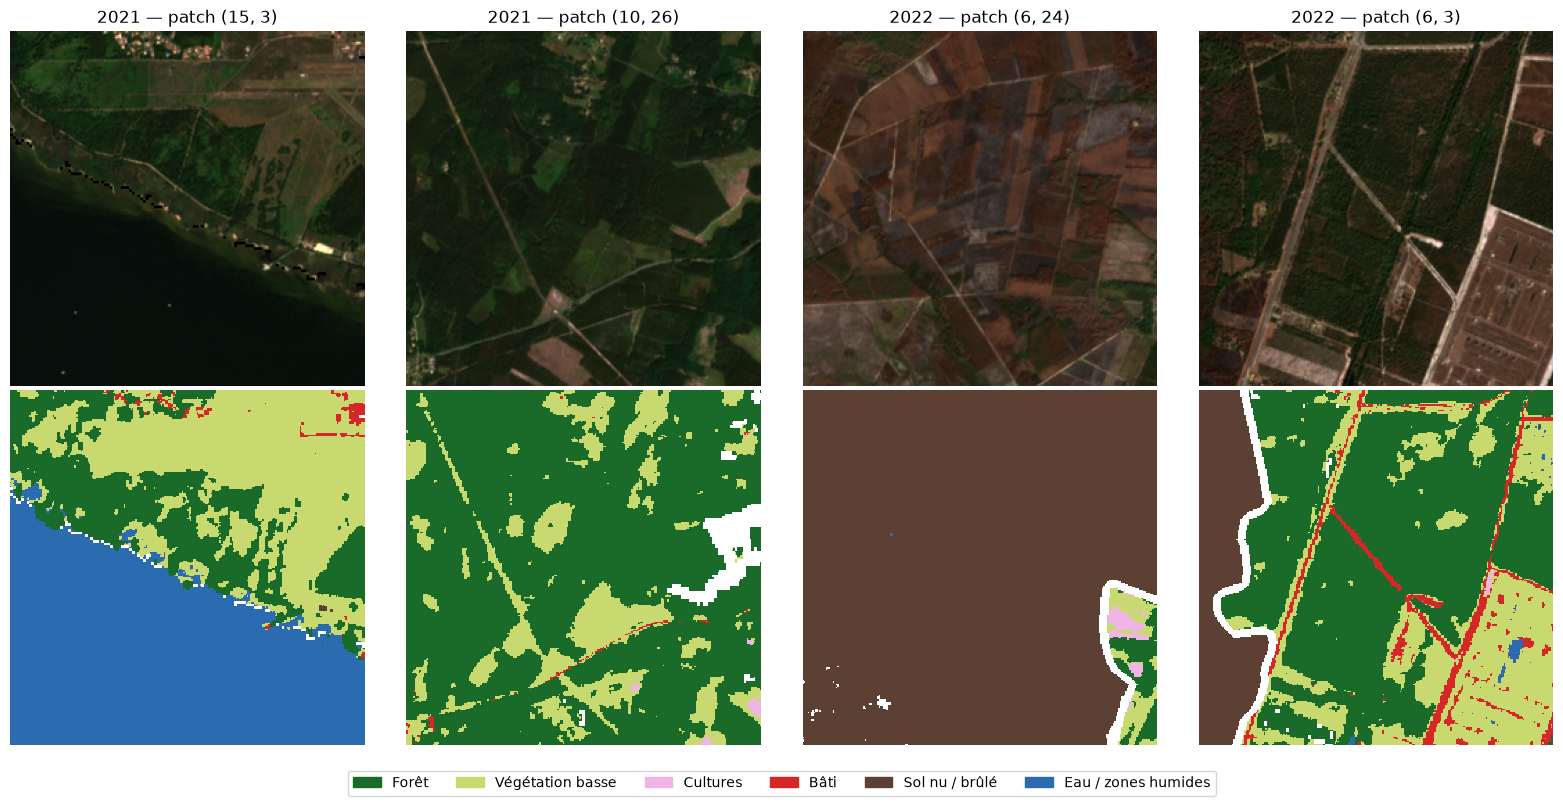

In [11]:
X_tr, Y_tr = donnees["train"]
annees_tr = np.array([p[0] for p in split["train"]])
rng = np.random.default_rng(0)
idx_2021 = rng.choice(np.flatnonzero(annees_tr == "2021"), size=2, replace=False)
avec_feu = np.flatnonzero((annees_tr == "2022") & ((Y_tr == BRULE).mean(axis=(1, 2)) > 0.10))
idx_2022 = rng.choice(avec_feu, size=min(2, len(avec_feu)), replace=False)
idx = np.concatenate([idx_2021, idx_2022])

fig, axes = plt.subplots(2, len(idx), figsize=(4 * len(idx), 8), squeeze=False)
for c, k in enumerate(idx):
    rgb = np.clip(np.stack([X_tr[k, 2], X_tr[k, 1], X_tr[k, 0]], axis=-1) / 0.25, 0, 1)
    axes[0, c].imshow(rgb)
    lab = np.ma.masked_equal(Y_tr[k], IGNORE)
    axes[1, c].imshow(lab, cmap=CMAP, vmin=0, vmax=N_CLASSES - 1, interpolation="nearest")
    a, i, j = split["train"][k]
    axes[0, c].set_title(f"{a} — patch {(i, j)}")
for ax in axes.flat:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=CLASSES[k][2]) for k in range(N_CLASSES)]
fig.legend(handles, NOMS, loc="lower center", ncol=N_CLASSES)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(FIG_DIR / "exemples_patchs.png", dpi=200, bbox_inches="tight")
plt.show()